In [1]:
from pathlib import Path
import pandas as pd
from tfrecord.torch.dataset import TFRecordDataset

In [2]:
description = {
    "id_seq": "int",
    "data_seq": "int",
    "timestamp": "float",
    "label": "int",
}

def tfrec_to_df(path):
    ds = TFRecordDataset(str(path), index_path=None, description=description)
    rows = []

    for rec in ds:
        row = {}
        for k, v in rec.items():
            row[k] = v.tolist() if hasattr(v, "tolist") else v
        row["source_file"] = Path(path).name
        rows.append(row)

    return pd.DataFrame(rows)

def tfrec_dir_to_df(dir_path):
    dir_path = Path(dir_path)
    paths = sorted(dir_path.glob("*.tfrec"), key=lambda p: int(p.stem))
    return pd.concat((tfrec_to_df(path) for path in paths), ignore_index=True)


In [3]:
train_2_df = tfrec_dir_to_df("../data/size_64_10/TFRecord_w64_s32/2/train")
val_2_df = tfrec_dir_to_df("../data/size_64_10/TFRecord_w64_s32/2/val")

In [4]:
print("Length of train_2_df:", len(train_2_df))
print("Length of val_2_df:", len(val_2_df))

Length of train_2_df: 61135
Length of val_2_df: 26215


In [5]:
train_3_df = tfrec_dir_to_df("../data/size_64_10/TFRecord_w64_s32/3/train")
val_3_df = tfrec_dir_to_df("../data/size_64_10/TFRecord_w64_s32/3/val")
test_3_df = tfrec_dir_to_df("../data/size_64_10/TFRecord_w64_s32/3/test")

In [6]:
print("Length of train_3_df:", len(train_3_df))
print("Length of val_3_df:", len(val_3_df))
print("Length of test_3_df:", len(test_3_df))

Length of train_3_df: 61135
Length of val_3_df: 13095
Length of test_3_df: 13120


In [7]:
print("Percentage of train_3_df: ", len(train_3_df) / (len(train_3_df) + len(val_3_df) + len(test_3_df)) * 100)
print("Percentage of val_3_df: ", len(val_3_df) / (len(train_3_df) + len(val_3_df) + len(test_3_df)) * 100)
print("Percentage of test_3_df: ", len(test_3_df) / (len(train_3_df) + len(val_3_df) + len(test_3_df)) * 100)

Percentage of train_3_df:  69.98855180309101
Percentage of val_3_df:  14.991413852318262
Percentage of test_3_df:  15.020034344590727


### Check distribution of attack types 

In [ ]:
# Statistics: number of records for each attack type
import pandas as pd
import matplotlib.pyplot as plt

classes = [
    'Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear',
    'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic'
]

label_to_class = dict(enumerate(classes))

def clean_label(x):
    # Robust conversion in case label is stored as list/array/tensor-like object
    if isinstance(x, (list, tuple)):
        return int(x[0])
    if hasattr(x, "tolist"):
        x = x.tolist()
        if isinstance(x, list):
            return int(x[0])
    return int(x)

def attack_statistics(dfs):
    all_counts = []

    for split_name, df in dfs.items():
        labels = df["label"].apply(clean_label)

        counts = (
            labels.value_counts()
            .reindex(range(len(classes)), fill_value=0)
            .astype(int)
        )

        temp = pd.DataFrame({
            "Split": split_name,
            "Label": counts.index,
            "Attack Type": [label_to_class[i] for i in counts.index],
            "Records": counts.values,
            "Percentage (%)": (counts.values / len(df) * 100).round(2)
        })

        all_counts.append(temp)

    return pd.concat(all_counts, ignore_index=True)

dfs = {
    "Train": train_3_df,
    "Validation": val_3_df,
    "Test": test_3_df
}

stats_long = attack_statistics(dfs)
display(stats_long)

stats_pivot = stats_long.pivot(
    index=["Label", "Attack Type"],
    columns="Split",
    values="Records"
).reset_index()

stats_pivot["Total"] = stats_pivot[["Train", "Validation", "Test"]].sum(axis=1)
display(stats_pivot)


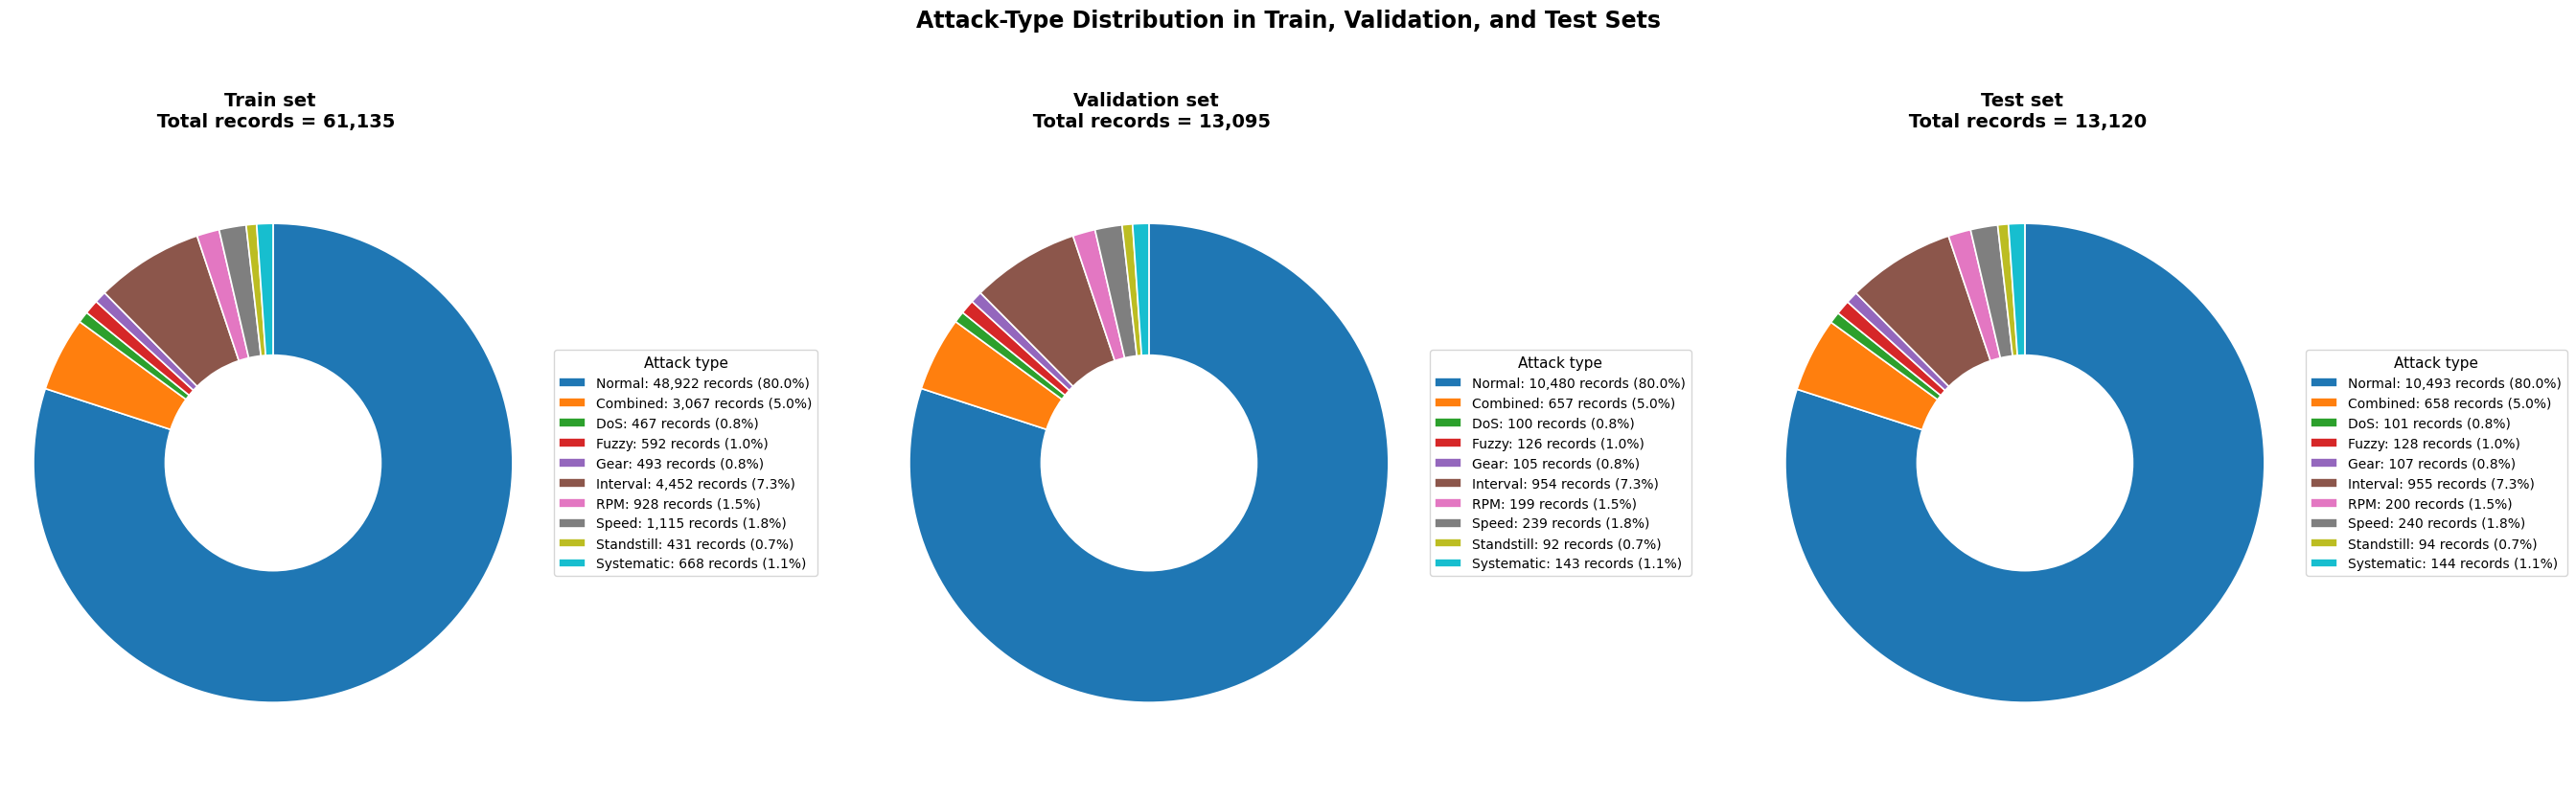

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(27, 8))

for ax, (split_name, df) in zip(axes, dfs.items()):
    labels = df["label"].apply(clean_label)

    counts = (
        labels.value_counts()
        .reindex(range(len(classes)), fill_value=0)
        .astype(int)
    )

    # Remove zero-count classes from the pie chart to keep it clean
    nonzero_counts = counts[counts > 0]
    total = int(nonzero_counts.sum())

    attack_names = [label_to_class[i] for i in nonzero_counts.index]
    legend_labels = [
        f"{name}: {count:,} records ({count / total * 100:.1f}%)"
        for name, count in zip(attack_names, nonzero_counts.values)
    ]

    wedges, texts = ax.pie(
        nonzero_counts.values,
        labels=None,                       # keep attack names out of the pie area
        autopct=None,                      # do not show percentages on the pie chart
        startangle=90,
        counterclock=False,
        wedgeprops={"width": 0.55, "edgecolor": "white", "linewidth": 1.2}
    )

    ax.set_title(f"{split_name} set \n Total records = {len(df):,}", fontsize=14, fontweight="bold")
    ax.axis("equal")

    # Put a clean legend beside each pie chart
    ax.legend(
        wedges,
        legend_labels,
        title="Attack type",
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        fontsize=10,
        title_fontsize=11,
        frameon=True
    )

plt.suptitle(
    "Attack-Type Distribution in Train, Validation, and Test Sets",
    fontsize=17,
    fontweight="bold",
    y=1.04
)
plt.tight_layout(w_pad=5)
plt.show()
